# Condiciones ambientales e incendios forestales: exploración comunal
**La Araucanía ? enero 2014–diciembre 2023.** Unidad: una comuna y un mes.

Objetivo: auditar los datos y encontrar relaciones y episodios ambientales para formular hipótesis sobre incendios. **No hay incendios, focos ni superficie quemada en este archivo:** ninguna correlación de este notebook mide ocurrencia de incendios ni demuestra causalidad. No se descargan datos ni se exportan archivos.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
BASE = Path.cwd()
if not (BASE / 'comunas_mensual.csv').exists():
    BASE = BASE / 'DeHecho' / 'datos_mensuales_2014_2023'
RUTA = BASE / 'comunas_mensual.csv'
meta = json.loads((BASE / 'metadatos.json').read_text(encoding='utf-8-sig'))
df_original = pd.read_csv(RUTA, dtype={'region_id':'string', 'commune_id':'string'}, encoding='utf-8-sig')
df = df_original.copy()
variables = list(meta['variables'])
cobertura = [x for x in df if x.endswith('_valid_area_pct')]
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Archivo:', RUTA.name, '| dimensiones:', df.shape)
hash_actual = hashlib.sha256(RUTA.read_bytes()).hexdigest()
print('SHA256 coincide con metadatos:', hash_actual == meta['files']['comunas_mensual.csv']['sha256'])
display(df.head())

Python: 3.14.8 | pandas: 3.0.6
Archivo: comunas_mensual.csv | dimensiones: (3840, 23)
SHA256 coincide con metadatos: True


,month,region_id,commune_id,commune_name,temperature_2m_c,dewpoint_2m_c,specific_humidity_2m_kgkg,wind_u_10m_ms,wind_v_10m_ms,meteorologia_mensual_valid_area_pct,wind_speed_lowest_model_ms,viento_nivel_modelo_mensual_valid_area_pct,soil_moisture_0_10cm_kgm2,soil_temperature_0_10cm_c,suelo_mensual_valid_area_pct,aod_550,aerosoles_mensual_valid_area_pct,precipitation_mm,precipitacion_mensual_valid_area_pct,temperature_monthly_peak_area_mean_c,temperature_monthly_max_c,relative_humidity_2m_pct,wind_speed_10m_ms
0,2014-01,09,09101,Temuco,17.297,8.730,0.007,2.025,1.609,100.000,5.460,100.000,22.888,16.873,100.000,0.089,100.000,79.101,100.000,37.462,37.890,64.312,3.502
1,2014-01,09,09102,Carahue,15.610,10.033,0.008,2.054,2.865,100.000,6.865,100.000,21.799,15.927,99.060,0.070,100.000,62.690,100.000,28.949,30.280,73.222,4.945
2,2014-01,09,09103,Cunco,15.966,6.604,0.007,1.113,0.314,100.000,4.547,100.000,17.328,14.439,100.000,0.064,100.000,115.766,100.000,35.769,37.890,61.352,2.268
3,2014-01,09,09104,Curarrehue,13.485,4.435,0.006,2.040,-0.035,100.000,5.323,100.000,17.665,11.733,100.000,0.055,100.000,120.782,100.000,31.448,35.270,61.465,3.008
4,2014-01,09,09105,Freire,17.139,8.853,0.007,1.367,0.806,100.000,4.597,100.000,18.634,16.980,100.000,0.074,100.000,85.936,100.000,37.083,37.890,65.748,2.200


## 1. Diccionario y alcance
Los resúmenes espaciales son ponderados por ?rea, salvo el máximo mensual espacial identificado por separado. Las comunas pueden compartir píxeles: 32 comunas no equivalen a 32 mediciones espaciales independientes. Los límites administrativos son una referencia fija de 2024.

In [2]:
descripciones = {
 'temperature_2m_c':'Temperatura del aire a 2 m',
 'dewpoint_2m_c':'Punto de rocío a 2 m',
 'specific_humidity_2m_kgkg':'Humedad específica a 2 m',
 'wind_u_10m_ms':'Componente zonal del viento a 10 m',
 'wind_v_10m_ms':'Componente meridional del viento a 10 m',
 'wind_speed_lowest_model_ms':'Velocidad del viento: nivel inferior del modelo',
 'soil_moisture_0_10cm_kgm2':'Agua del suelo de 0 a 10 cm; no es porcentaje',
 'soil_temperature_0_10cm_c':'Temperatura del suelo de 0 a 10 cm',
 'aod_550':'Espesor ?ptico de aerosoles a 550 nm; no identifica su origen',
 'precipitation_mm':'Precipitación acumulada mensual',
 'temperature_monthly_max_c':'Máximo entre extremos mensuales de píxeles intersectados',
 'relative_humidity_2m_pct':'Humedad relativa a 2 m',
 'wind_speed_10m_ms':'Velocidad escalar del viento a 10 m',
 'temperature_monthly_peak_area_mean_c':'Media por ?rea de extremos mensuales de píxeles'}
unidades = {v: meta['variables'][v]['unit'].replace('?C','°C').replace('kg/m?','kg/m²') for v in variables}
display(pd.DataFrame({'descripcion':descripciones,'unidad':unidades}).rename_axis('variable'))

,descripcion,unidad
variable,,
temperature_2m_c,Temperatura del aire a 2 m,°C
dewpoint_2m_c,Punto de rocío a 2 m,°C
specific_humidity_2m_kgkg,Humedad específica a 2 m,kg/kg
wind_u_10m_ms,Componente zonal del viento a 10 m,m/s
wind_v_10m_ms,Componente meridional del viento a 10 m,m/s
wind_speed_lowest_model_ms,Velocidad del viento: nivel inferior del modelo,m/s
soil_moisture_0_10cm_kgm2,Agua del suelo de 0 a 10 cm; no es porcentaje,kg/m²
soil_temperature_0_10cm_c,Temperatura del suelo de 0 a 10 cm,°C
aod_550,Espesor ?ptico de aerosoles a 550 nm; no ident...,1


In [3]:
# Limpieza conservadora: no imputar, recortar extremos ni eliminar filas automáticamente.
columnas_antes = df.columns.tolist()
df.columns = df.columns.str.strip()
assert not df.columns.duplicated().any(), 'Nombres de columnas duplicados'
for col in ['region_id','commune_id','commune_name']:
    df[col] = df[col].astype('string').str.strip()
fecha = pd.to_datetime(df['month'], format='%Y-%m', errors='coerce')
conversiones = {}
for col in variables + cobertura:
    convertido = pd.to_numeric(df[col], errors='coerce')
    conversiones[col] = int((df[col].notna() & convertido.isna()).sum())
    df[col] = convertido
calidad = pd.DataFrame({
    'tipo':df.dtypes.astype(str), 'nulos':df.isna().sum(),
    'unicos':df.nunique(), 'conversiones_fallidas':pd.Series(conversiones)
}).fillna({'conversiones_fallidas':0})
display(calidad)
meses_esperados = pd.period_range(meta['period']['start'],meta['period']['end'],freq='M')
indice_esperado = pd.MultiIndex.from_product([df.commune_id.dropna().unique(), meses_esperados.astype(str)],names=['commune_id','month'])
indice_real = pd.MultiIndex.from_frame(df[['commune_id','month']])
controles = {
 'fechas_invalidas':int(fecha.isna().sum()),
 'filas_duplicadas':int(df.duplicated().sum()),
 'claves_comuna_mes_duplicadas':int(df.duplicated(['commune_id','month']).sum()),
 'comuna_mes_faltantes':len(indice_esperado.difference(indice_real)),
 'claves_fuera_de_periodo':len(indice_real.difference(indice_esperado)),
 'conversiones_numericas_fallidas':sum(conversiones.values()),
 'valores_numericos_infinitos':int(np.isinf(df[variables+cobertura]).sum().sum()),
 'codigos_comuna_invalidos':int((~df.commune_id.str.fullmatch(r'\d{5}',na=False)).sum()),
 'regiones_distintas_de_09':int(df.region_id.ne('09').sum()),
 'codigos_con_varios_nombres':int((df.groupby('commune_id').commune_name.nunique()>1).sum()),
 'comunas_fuera_de_las_32_esperadas':abs(df.commune_id.nunique()-32),
}
display(pd.Series(controles,name='incidencias').to_frame())
assert not any(controles.values()), 'Revisar controles antes de continuar'
assert not df[variables+cobertura].isna().any().any(), 'Hay datos faltantes; revisar antes de continuar'
df['fecha'] = fecha
df['mes'] = fecha.dt.month
df['anio'] = fecha.dt.year
df = df.sort_values(['commune_id','fecha']).reset_index(drop=True)
print('Panel completo:',len(df),'registros;',df.commune_id.nunique(),'comunas;',df.month.nunique(),'meses.')
print('No se eliminaron filas ni se imputaron valores.')

,tipo,nulos,unicos,conversiones_fallidas
aerosoles_mensual_valid_area_pct,float64,0,1,0.000
aod_550,float64,0,3741,0.000
commune_id,string,0,32,0.000
commune_name,string,0,32,0.000
dewpoint_2m_c,float64,0,3125,0.000
meteorologia_mensual_valid_area_pct,float64,0,1,0.000
month,str,0,120,0.000
precipitacion_mensual_valid_area_pct,float64,0,1,0.000
precipitation_mm,float64,0,3806,0.000
region_id,string,0,1,0.000


,incidencias
fechas_invalidas,0
filas_duplicadas,0
claves_comuna_mes_duplicadas,0
comuna_mes_faltantes,0
claves_fuera_de_periodo,0
conversiones_numericas_fallidas,0
valores_numericos_infinitos,0
codigos_comuna_invalidos,0
regiones_distintas_de_09,0
codigos_con_varios_nombres,0


Panel completo: 3840 registros; 32 comunas; 120 meses.
No se eliminaron filas ni se imputaron valores.


In [4]:
reglas = {
 'humedad_relativa_fuera_0_100': ~df.relative_humidity_2m_pct.between(0,100),
 'precipitacion_negativa': df.precipitation_mm < 0,
 'agua_suelo_negativa': df.soil_moisture_0_10cm_kgm2 < 0,
 'aod_negativo': df.aod_550 < 0,
 'velocidad_10m_negativa': df.wind_speed_10m_ms < 0,
 'velocidad_modelo_negativa': df.wind_speed_lowest_model_ms < 0,
 'rocio_supera_temperatura': df.dewpoint_2m_c > df.temperature_2m_c + 0.1,
 'media_extremos_supera_maximo': df.temperature_monthly_peak_area_mean_c > df.temperature_monthly_max_c + 0.01,
 'coberturas_fuera_0_100': (~df[cobertura].ge(0) | ~df[cobertura].le(100)).any(axis=1),
}
display(pd.Series({k:int(v.sum()) for k,v in reglas.items()},name='registros_a_revisar').to_frame())
display(df[variables].describe(percentiles=[.01,.25,.5,.75,.99]).T)
# Los valores negativos de temperatura y de componentes U/V no son errores.
resumen_cobertura = pd.DataFrame({
 'minimo_pct':df[cobertura].min(), 'media_pct':df[cobertura].mean(),
 'registros_menor_90pct':df[cobertura].lt(90).sum(),
 'registros_menor_80pct':df[cobertura].lt(80).sum()})
display(resumen_cobertura)
display(df.nsmallest(12,'suelo_mensual_valid_area_pct')[['month','commune_name','suelo_mensual_valid_area_pct','soil_moisture_0_10cm_kgm2']])

,registros_a_revisar
humedad_relativa_fuera_0_100,0
precipitacion_negativa,0
agua_suelo_negativa,0
aod_negativo,0
velocidad_10m_negativa,0
velocidad_modelo_negativa,0
rocio_supera_temperatura,0
media_extremos_supera_maximo,0
coberturas_fuera_0_100,0


,count,mean,std,min,1%,25%,50%,75%,99%,max
temperature_2m_c,"3,840.000",10.932,4.269,-2.103,1.538,7.562,10.433,14.591,18.999,21.394
dewpoint_2m_c,"3,840.000",6.063,2.646,-3.596,-1.350,4.559,6.215,7.966,11.094,12.535
specific_humidity_2m_kgkg,"3,840.000",0.006,0.001,0.004,0.004,0.006,0.006,0.007,0.009,0.009
wind_u_10m_ms,"3,840.000",0.783,0.672,-1.637,-0.867,0.304,0.787,1.249,2.286,2.959
wind_v_10m_ms,"3,840.000",0.233,1.229,-2.978,-2.065,-0.697,0.121,1.017,3.398,4.668
wind_speed_lowest_model_ms,"3,840.000",4.901,0.723,3.288,3.502,4.375,4.837,5.373,6.743,7.245
soil_moisture_0_10cm_kgm2,"3,840.000",27.228,7.657,9.094,11.369,21.000,28.346,33.380,40.095,43.133
soil_temperature_0_10cm_c,"3,840.000",10.366,4.519,-1.372,0.198,6.799,9.874,14.111,19.061,22.348
aod_550,"3,840.000",0.075,0.023,0.022,0.032,0.060,0.072,0.086,0.158,0.380
precipitation_mm,"3,840.000",102.330,91.223,0.237,2.812,28.770,71.290,157.358,350.678,442.834


,minimo_pct,media_pct,registros_menor_90pct,registros_menor_80pct
meteorologia_mensual_valid_area_pct,100.000,100.000,0,0
viento_nivel_modelo_mensual_valid_area_pct,100.000,100.000,0,0
suelo_mensual_valid_area_pct,36.490,97.504,240,120
aerosoles_mensual_valid_area_pct,100.000,100.000,0,0
precipitacion_mensual_valid_area_pct,100.000,100.000,0,0


,month,commune_name,suelo_mensual_valid_area_pct,soil_moisture_0_10cm_kgm2
1800,2014-01,Saavedra,36.490,23.877
1801,2014-02,Saavedra,36.490,23.521
1802,2014-03,Saavedra,36.490,24.813
1803,2014-04,Saavedra,36.490,31.207
1804,2014-05,Saavedra,36.490,35.426
1805,2014-06,Saavedra,36.490,39.261
1806,2014-07,Saavedra,36.490,39.110
1807,2014-08,Saavedra,36.490,39.737
1808,2014-09,Saavedra,36.490,38.821
1809,2014-10,Saavedra,36.490,36.819


**Criterio de calidad:** los extremos se conservan: una regla IQR aplicada a todo el panel puede marcar variabilidad espacial o estacional legítima. La cobertura del suelo se examina por separado y se repiten sus correlaciones con cobertura ≥90 %. Ese umbral es una decisión exploratoria, no una garantía de exactitud. Los chequeos de rango detectan inconsistencias básicas, no validan los sensores.

## 2. Estacionalidad y variación espacial
Las medias entre comunas dan el mismo peso a cada comuna: no son promedios regionales ponderados por superficie. No se suman temperaturas, humedades ni aerosoles.

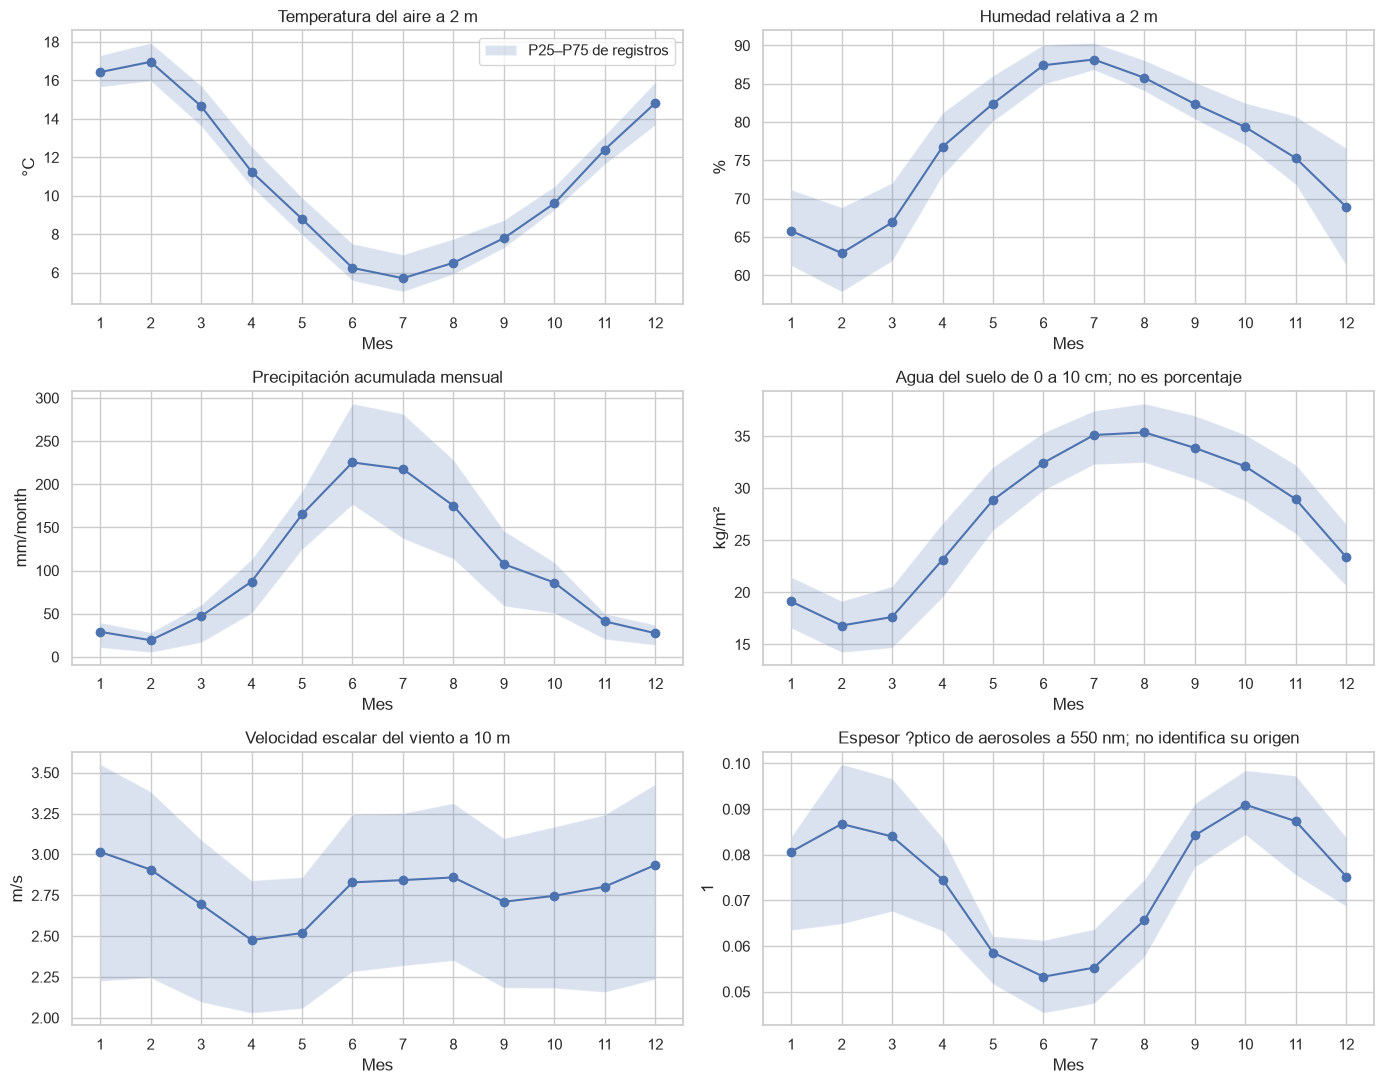

,temperature_2m_c,relative_humidity_2m_pct,precipitation_mm,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,aod_550
commune_name,,,,,,
Angol,12.183,73.866,79.401,26.762,3.264,0.075
Carahue,11.411,81.224,91.983,29.412,4.043,0.075
Cholchol,11.325,80.166,84.489,30.508,3.813,0.077
Collipulli,11.529,70.183,101.733,24.604,2.353,0.075
Cunco,9.948,75.638,125.368,23.807,2.104,0.068
Curacautín,9.503,71.561,113.320,22.100,2.209,0.065
Curarrehue,7.285,76.220,98.038,24.422,2.811,0.054
Ercilla,12.081,72.987,94.736,28.736,2.584,0.082
Freire,11.598,79.029,114.630,25.716,1.925,0.081


In [5]:
principales = ['temperature_2m_c','relative_humidity_2m_pct','precipitation_mm','soil_moisture_0_10cm_kgm2','wind_speed_10m_ms','aod_550']
fig, axs = plt.subplots(3,2,figsize=(14,11))
for ax,col in zip(axs.flat,principales):
    por_mes = df.groupby('mes')[col]
    media = por_mes.mean()
    ax.plot(media.index,media,marker='o')
    ax.fill_between(media.index,por_mes.quantile(.25),por_mes.quantile(.75),alpha=.2,label='P25–P75 de registros')
    ax.set(title=descripciones[col],xlabel='Mes',ylabel=unidades[col],xticks=range(1,13))
axs.flat[0].legend()
plt.tight_layout(); plt.show()
resumen_comunas = df.groupby('commune_name')[principales].mean()
display(resumen_comunas)

## 3. Correlaciones: datos originales y anomalías
Se calculan Pearson (relación lineal) y Spearman (relación monotónica, menos sensible a extremos). Se excluyen códigos y coberturas.

Las **anomalías** restan a cada observación la media de su propia comuna y mes calendario en 2014–2023. Así, un enero se compara con otros eneros de esa comuna. Esto reduce las diferencias espaciales constantes y la estacionalidad media; no elimina tendencias, dependencia temporal ni factores omitidos. Cada climatología tiene solo diez observaciones y usa todo el período: es descriptiva, no una transformación lista para pronóstico.

No se reportan p-valores que supongan 3.840 observaciones independientes. Las relaciones se seleccionan exploratoriamente y necesitan validación externa.

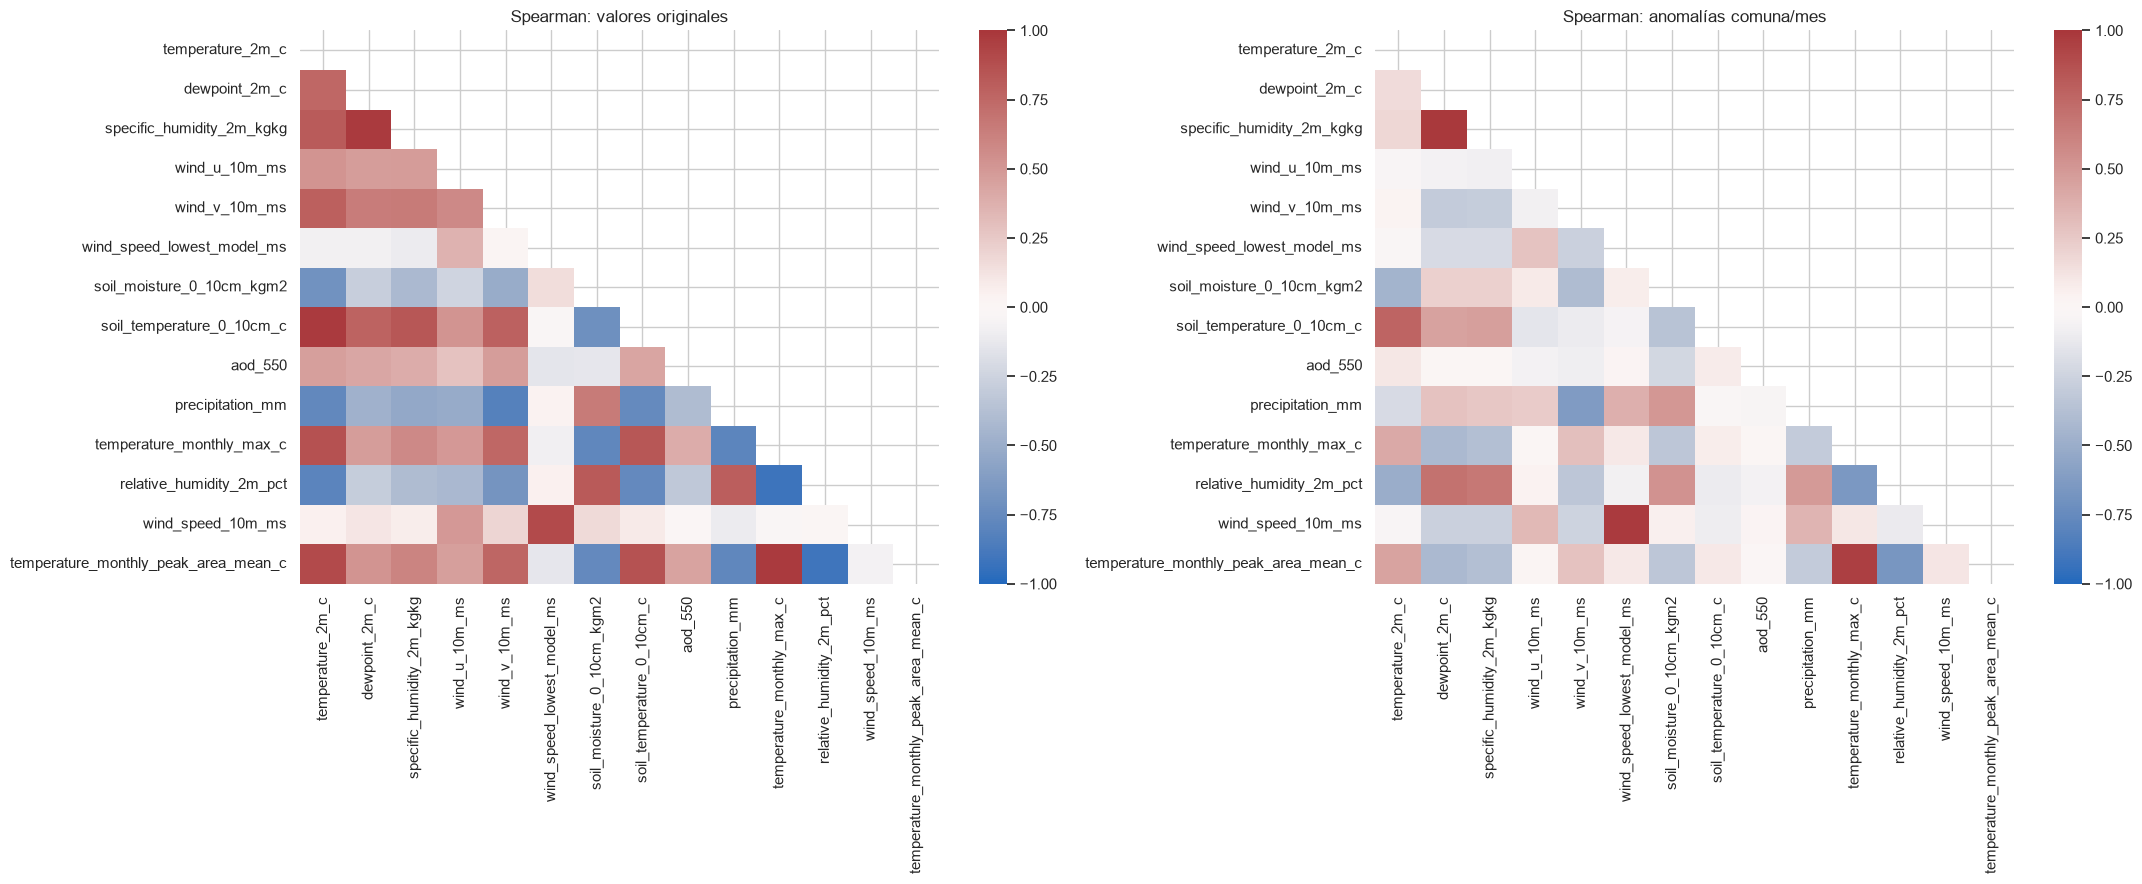

,variable_1,variable_2,spearman_original,spearman_anomalia,pearson_anomalia,cambio_absoluto
13,dewpoint_2m_c,specific_humidity_2m_kgkg,0.977,0.990,0.989,-0.013
61,wind_speed_lowest_model_ms,wind_speed_10m_ms,0.904,0.982,0.978,-0.078
87,temperature_monthly_max_c,temperature_monthly_peak_area_mean_c,0.980,0.953,0.958,0.026
6,temperature_2m_c,soil_temperature_0_10cm_c,0.980,0.771,0.768,0.209
22,dewpoint_2m_c,relative_humidity_2m_pct,-0.292,0.699,0.734,-0.407
89,relative_humidity_2m_pct,temperature_monthly_peak_area_mean_c,-0.910,-0.671,-0.700,0.239
33,specific_humidity_2m_kgkg,relative_humidity_2m_pct,-0.404,0.666,0.709,-0.262
85,temperature_monthly_max_c,relative_humidity_2m_pct,-0.918,-0.650,-0.676,0.268
50,wind_v_10m_ms,precipitation_mm,-0.821,-0.630,-0.626,0.191
67,soil_moisture_0_10cm_kgm2,relative_humidity_2m_pct,0.822,0.526,0.500,0.296


Relaciones que más se debilitan al descontar la estacionalidad y el nivel de cada comuna:


,variable_1,variable_2,spearman_original,spearman_anomalia,pearson_anomalia,cambio_absoluto
75,soil_temperature_0_10cm_c,temperature_monthly_peak_area_mean_c,0.866,0.095,0.145,0.772
72,soil_temperature_0_10cm_c,temperature_monthly_max_c,0.843,0.075,0.132,0.768
3,temperature_2m_c,wind_v_10m_ms,0.792,0.038,0.019,0.754
71,soil_temperature_0_10cm_c,precipitation_mm,-0.751,-0.018,0.026,0.733
48,wind_v_10m_ms,soil_temperature_0_10cm_c,0.787,-0.103,-0.110,0.684
73,soil_temperature_0_10cm_c,relative_humidity_2m_pct,-0.764,-0.108,-0.184,0.656
1,temperature_2m_c,specific_humidity_2m_kgkg,0.819,0.186,0.062,0.633
0,temperature_2m_c,dewpoint_2m_c,0.755,0.157,0.047,0.599
8,temperature_2m_c,precipitation_mm,-0.772,-0.209,-0.160,0.563
36,wind_u_10m_ms,wind_v_10m_ms,0.574,-0.077,-0.121,0.497


In [6]:
anom = df[variables] - df.groupby(['commune_id','mes'])[variables].transform('mean')
corr_raw = df[variables].corr(method='spearman')
corr_anom = anom.corr(method='spearman')
fig,axs = plt.subplots(1,2,figsize=(22,9))
for ax,mat,titulo in [(axs[0],corr_raw,'Spearman: valores originales'),(axs[1],corr_anom,'Spearman: anomalías comuna/mes')]:
    sns.heatmap(mat,mask=np.triu(np.ones(mat.shape,dtype=bool)),vmin=-1,vmax=1,center=0,cmap='vlag',ax=ax)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()
pares=[]
for i,a in enumerate(variables):
    for b in variables[i+1:]:
        pares.append({'variable_1':a,'variable_2':b,
          'spearman_original':corr_raw.loc[a,b],
          'spearman_anomalia':corr_anom.loc[a,b],
          'pearson_anomalia':anom[a].corr(anom[b]),
          'cambio_absoluto':abs(corr_raw.loc[a,b])-abs(corr_anom.loc[a,b])})
pares = pd.DataFrame(pares)
display(pares.assign(fuerza=pares.spearman_anomalia.abs()).sort_values('fuerza',ascending=False).head(20).drop(columns='fuerza'))
print('Relaciones que más se debilitan al descontar la estacionalidad y el nivel de cada comuna:')
display(pares.sort_values('cambio_absoluto',ascending=False).head(10))

In [7]:
# Sensibilidad de las relaciones con suelo a la cobertura espacial.
filas=[]
for suelo in ['soil_moisture_0_10cm_kgm2','soil_temperature_0_10cm_c']:
    for otra in principales:
        if otra == suelo: continue
        for etiqueta,mask in [('todas',pd.Series(True,index=df.index)),('suelo >=90%',df.suelo_mensual_valid_area_pct.ge(90))]:
            filas.append({'suelo':suelo,'otra_variable':otra,'muestra':etiqueta,'n':int(mask.sum()),
                'spearman_anomalia':anom.loc[mask,suelo].corr(anom.loc[mask,otra],method='spearman')})
display(pd.DataFrame(filas))

,suelo,otra_variable,muestra,n,spearman_anomalia
0,soil_moisture_0_10cm_kgm2,temperature_2m_c,todas,3840,-0.460
1,soil_moisture_0_10cm_kgm2,temperature_2m_c,suelo >=90%,3600,-0.471
2,soil_moisture_0_10cm_kgm2,relative_humidity_2m_pct,todas,3840,0.526
3,soil_moisture_0_10cm_kgm2,relative_humidity_2m_pct,suelo >=90%,3600,0.532
4,soil_moisture_0_10cm_kgm2,precipitation_mm,todas,3840,0.505
5,soil_moisture_0_10cm_kgm2,precipitation_mm,suelo >=90%,3600,0.502
6,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,todas,3840,0.059
7,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,suelo >=90%,3600,0.054
8,soil_moisture_0_10cm_kgm2,aod_550,todas,3840,-0.234
9,soil_moisture_0_10cm_kgm2,aod_550,suelo >=90%,3600,-0.238


## 4. Relaciones relevantes y consistencia entre comunas
Se examinan pares que conectan calor, agua disponible, viento y aerosoles. Las diferencias entre comunas ayudan a evitar conclusiones basadas ?nicamente en una correlación global. AOD mide aerosoles de diversos orígenes; una asociación con sequedad o calor no atribuye esos aerosoles a incendios.

,x,y,rho_original,rho_anomalia,mediana_rho_comunal,min_rho_comunal,max_rho_comunal,comunas_rho_positivo,comunas_rho_negativo
0,temperature_2m_c,relative_humidity_2m_pct,-0.800,-0.506,-0.502,-0.670,-0.183,0,32
1,precipitation_mm,soil_moisture_0_10cm_kgm2,0.654,0.505,0.536,0.235,0.586,32,0
2,temperature_monthly_peak_area_mean_c,soil_moisture_0_10cm_kgm2,-0.766,-0.331,-0.337,-0.434,-0.199,0,32
3,wind_speed_10m_ms,relative_humidity_2m_pct,0.015,-0.112,-0.151,-0.258,0.255,3,29
4,aod_550,precipitation_mm,-0.402,-0.045,-0.060,-0.174,0.072,8,24
5,aod_550,soil_moisture_0_10cm_kgm2,-0.133,-0.234,-0.222,-0.355,-0.118,0,32


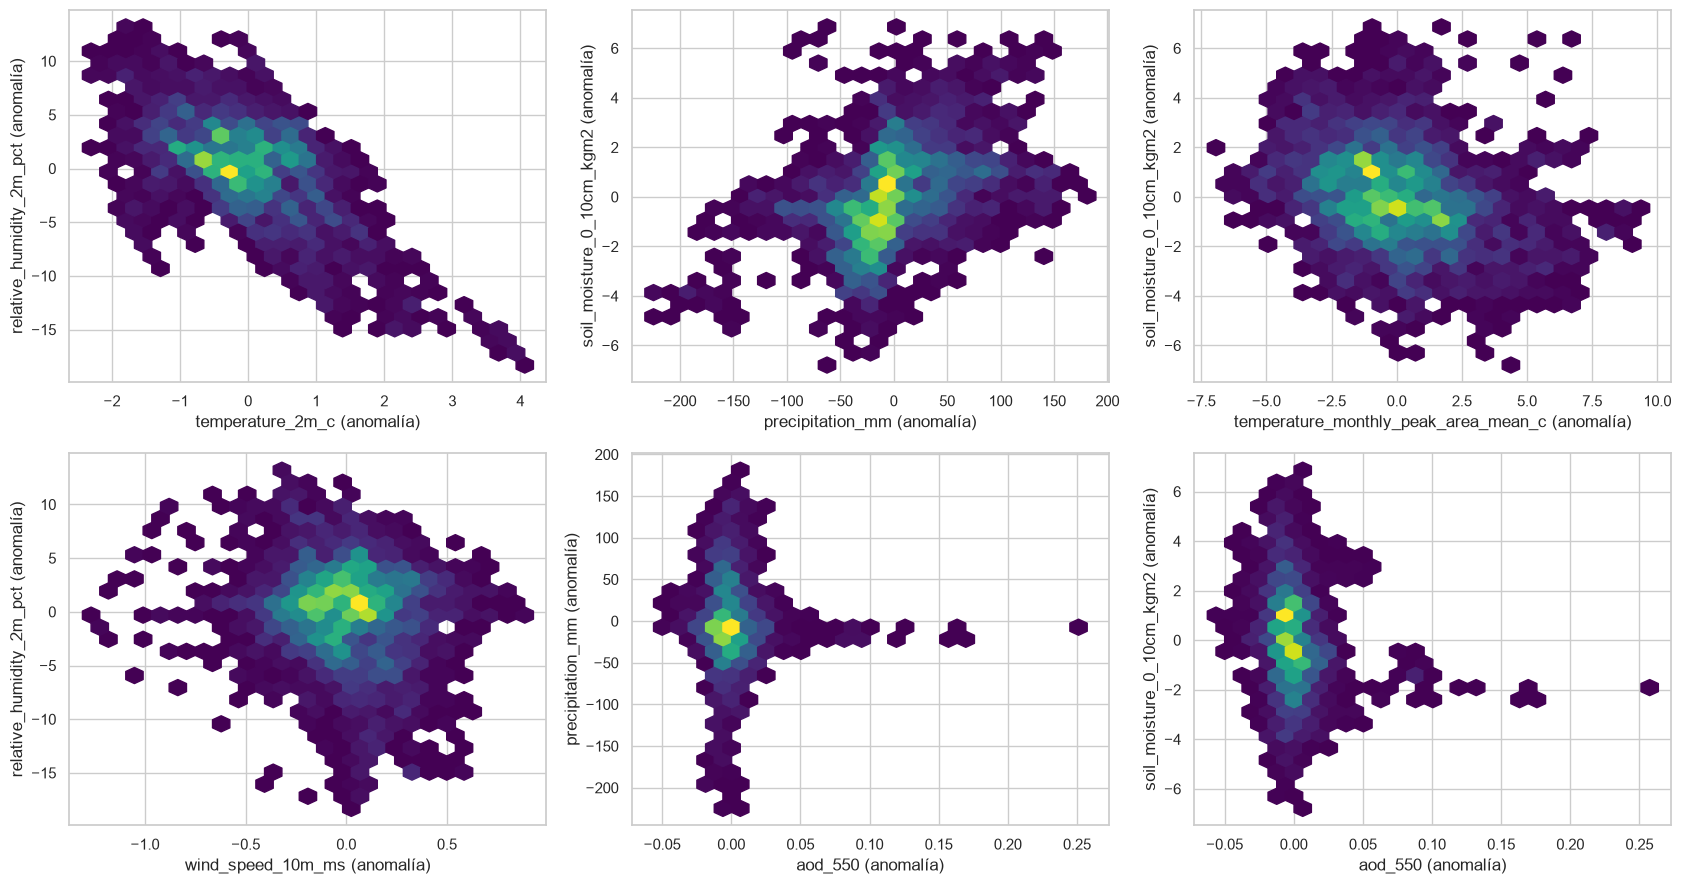

In [8]:
hipotesis = [
 ('temperature_2m_c','relative_humidity_2m_pct'),
 ('precipitation_mm','soil_moisture_0_10cm_kgm2'),
 ('temperature_monthly_peak_area_mean_c','soil_moisture_0_10cm_kgm2'),
 ('wind_speed_10m_ms','relative_humidity_2m_pct'),
 ('aod_550','precipitation_mm'),
 ('aod_550','soil_moisture_0_10cm_kgm2')]
filas=[]
for a,b in hipotesis:
    comunales = pd.Series({com:anom.loc[g.index,a].corr(anom.loc[g.index,b],method='spearman') for com,g in df.groupby('commune_name')})
    filas.append({'x':a,'y':b,'rho_original':df[a].corr(df[b],method='spearman'),
       'rho_anomalia':anom[a].corr(anom[b],method='spearman'),
       'mediana_rho_comunal':comunales.median(),'min_rho_comunal':comunales.min(),
       'max_rho_comunal':comunales.max(),'comunas_rho_positivo':int(comunales.gt(0).sum()),
       'comunas_rho_negativo':int(comunales.lt(0).sum())})
relaciones = pd.DataFrame(filas)
display(relaciones)
fig,axs=plt.subplots(2,3,figsize=(17,9))
for ax,(a,b) in zip(axs.flat,hipotesis):
    ax.hexbin(anom[a],anom[b],gridsize=25,mincnt=1,cmap='viridis')
    ax.set(xlabel=a+' (anomalía)',ylabel=b+' (anomalía)')
plt.tight_layout(); plt.show()

## 5. Rezagos: precipitación previa y humedad del suelo
Se compara la precipitación del mes t−k con el suelo en t, siempre dentro de la misma comuna y después de descontar la estacionalidad. Un rezago positivo significa que la lluvia antecede a la medición del suelo. El panel completo mensual fue verificado antes de desplazar las series. Las correlaciones rezagadas no prueban causalidad.

,rezago_meses,n_pares,rho_lluvia_previa_suelo_actual
0,0,3840,0.505
1,1,3808,0.460
2,2,3776,0.346
3,3,3744,0.348


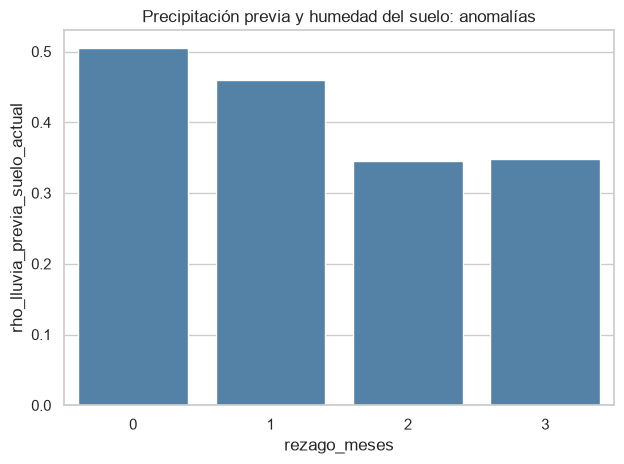

In [9]:
rezagos=[]
for k in range(4):
    lluvia_previa = anom['precipitation_mm'].groupby(df.commune_id).shift(k)
    valido=lluvia_previa.notna() & anom.soil_moisture_0_10cm_kgm2.notna()
    rezagos.append({'rezago_meses':k,'n_pares':int(valido.sum()),
      'rho_lluvia_previa_suelo_actual':lluvia_previa[valido].corr(anom.loc[valido,'soil_moisture_0_10cm_kgm2'],method='spearman')})
rezagos=pd.DataFrame(rezagos)
display(rezagos)
sns.barplot(data=rezagos,x='rezago_meses',y='rho_lluvia_previa_suelo_actual',color='steelblue')
plt.axhline(0,color='black',lw=.8); plt.title('Precipitación previa y humedad del suelo: anomalías')
plt.tight_layout(); plt.show()

## 6. Coincidencias de calor, sequedad y viento
Se identifican condiciones relativas a la historia de cada comuna: temperatura extrema ≥P75, humedad relativa ≤P25, agua del suelo ≤P25 y viento ≥P75. **No es un ?ndice de peligro validado, una probabilidad de incendio ni un umbral operativo.** Cada condición suma un punto solo para ordenar coincidencias; las variables no son independientes.

Se repite la búsqueda usando anomalías por comuna/mes calendario para reducir el predominio del verano. Con diez años, esos percentiles por mes son poco estables; los resultados son candidatos para investigar. Se exige cobertura del suelo ≥90 % al listar episodios.

Registros elegibles: 3600 | con 3–4 coincidencias anómalas: 591


,month,commune_name,coincidencias_anom,anom_temperatura_extrema,anom_suelo,temperature_monthly_peak_area_mean_c,relative_humidity_2m_pct,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,aod_550
2266,2022-11,Vilcún,4,8.127,-1.319,36.044,56.547,24.954,2.301,0.085
1055,2021-12,Loncoche,4,7.105,-4.004,37.433,58.201,23.913,2.032,0.080
1307,2022-12,Nueva Imperial,4,6.756,-1.919,33.907,65.587,21.949,4.007,0.070
2507,2022-12,Cholchol,4,6.660,-1.712,34.408,63.250,22.918,4.722,0.070
2752,2023-05,Collipulli,4,6.658,-2.288,29.112,66.155,24.047,2.233,0.061
1415,2021-12,Padre Las Casas,4,6.512,-3.577,37.779,58.489,19.576,2.150,0.086
3347,2022-12,Lumaco,4,6.458,-2.443,34.086,63.106,22.032,5.021,0.069
2992,2023-05,Ercilla,4,6.424,-2.509,28.725,70.825,28.304,2.416,0.066
1535,2021-12,Perquenco,4,6.410,-4.245,37.130,57.030,14.599,3.380,0.096
95,2021-12,Temuco,4,6.406,-4.193,37.153,57.273,24.039,3.252,0.095


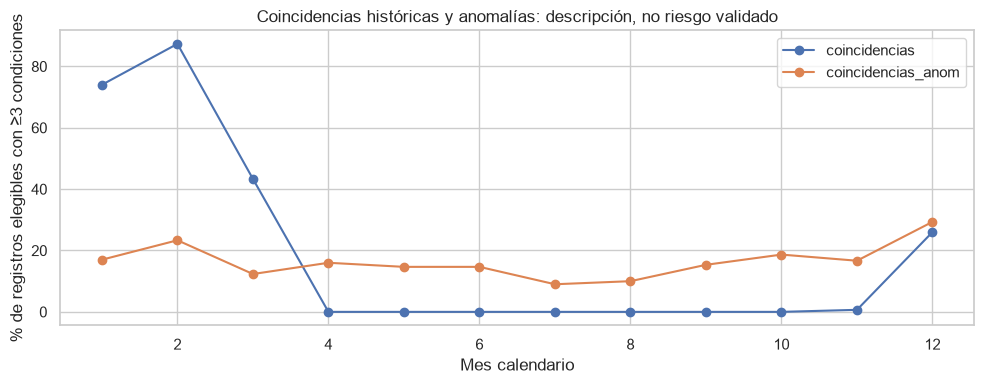

In [10]:
condiciones = {
 'calor':('temperature_monthly_peak_area_mean_c',.75,'alto'),
 'aire_seco':('relative_humidity_2m_pct',.25,'bajo'),
 'suelo_seco':('soil_moisture_0_10cm_kgm2',.25,'bajo'),
 'viento':('wind_speed_10m_ms',.75,'alto')}
for nombre,(v,q,direccion) in condiciones.items():
    umbral=df.groupby('commune_id')[v].transform(lambda x:x.quantile(q))
    df[nombre] = df[v].ge(umbral) if direccion=='alto' else df[v].le(umbral)
    umbral_a=anom[v].groupby([df.commune_id,df.mes]).transform(lambda x:x.quantile(q))
    df[nombre+'_anom']=anom[v].ge(umbral_a) if direccion=='alto' else anom[v].le(umbral_a)
df['coincidencias'] = df[list(condiciones)].sum(axis=1)
df['coincidencias_anom'] = df[[x+'_anom' for x in condiciones]].sum(axis=1)
elegibles=df.suelo_mensual_valid_area_pct.ge(90)
episodios=df.loc[elegibles & df.coincidencias_anom.ge(3)].copy()
episodios['anom_temperatura_extrema']=anom.loc[episodios.index,'temperature_monthly_peak_area_mean_c']
episodios['anom_suelo']=anom.loc[episodios.index,'soil_moisture_0_10cm_kgm2']
episodios=episodios.sort_values(['coincidencias_anom','anom_temperatura_extrema'],ascending=False)
print('Registros elegibles:',int(elegibles.sum()),'| con 3–4 coincidencias anómalas:',len(episodios))
display(episodios[['month','commune_name','coincidencias_anom','anom_temperatura_extrema','anom_suelo',
 'temperature_monthly_peak_area_mean_c','relative_humidity_2m_pct','soil_moisture_0_10cm_kgm2','wind_speed_10m_ms','aod_550']].head(25))
frecuencia=df.loc[elegibles].groupby('mes')[['coincidencias','coincidencias_anom']].agg(lambda x:100*x.ge(3).mean())
frecuencia.plot(marker='o',figsize=(10,4))
plt.ylabel('% de registros elegibles con ≥3 condiciones'); plt.xlabel('Mes calendario')
plt.title('Coincidencias históricas y anomalías: descripción, no riesgo validado')
plt.tight_layout(); plt.show()

## 7. Meses con condiciones anómalas compartidas
El porcentaje de comunas afectadas describe extensión administrativa, no superficie afectada ni eventos independientes. Se muestra el número de comunas elegibles para que cambios de cobertura no se confundan con cambios ambientales.

,comunas_elegibles,comunas_3_condiciones,coincidencias_promedio,porcentaje_comunas
fecha,,,,
2021-08-01,30,30,3.267,100.000
2021-12-01,30,30,3.633,100.000
2022-12-01,30,30,3.933,100.000
2023-02-01,30,30,3.767,100.000
2020-04-01,30,29,3.667,96.667
2023-06-01,30,29,3.733,96.667
2023-05-01,30,28,3.367,93.333
2023-12-01,30,28,2.933,93.333
2019-02-01,30,27,3.200,90.000


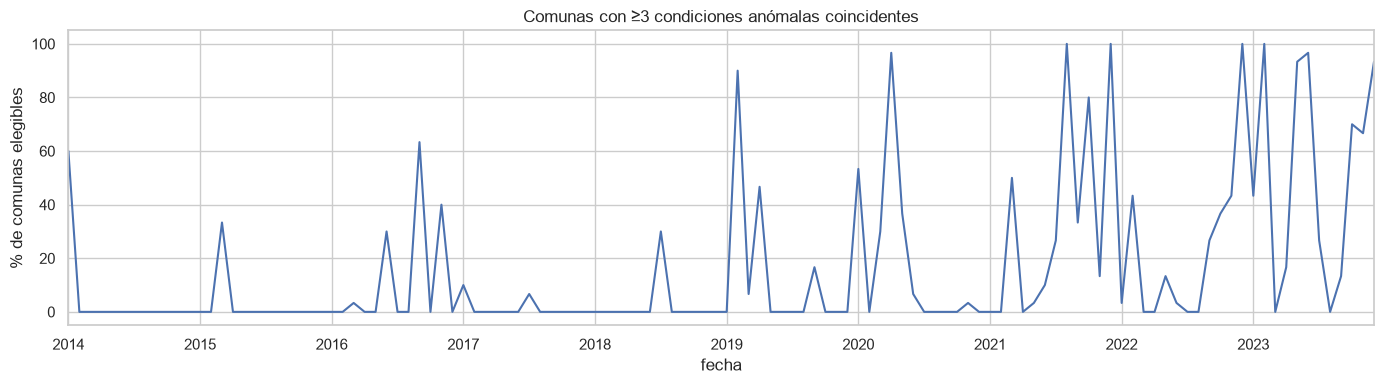

,temperature_2m_c,relative_humidity_2m_pct,precipitation_mm,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,aod_550
temperature_2m_c,1.000,-0.472,-0.225,-0.517,-0.053,0.123
relative_humidity_2m_pct,-0.472,1.000,0.547,0.583,-0.086,-0.066
precipitation_mm,-0.225,0.547,1.000,0.541,0.409,-0.049
soil_moisture_0_10cm_kgm2,-0.517,0.583,0.541,1.000,0.072,-0.255
wind_speed_10m_ms,-0.053,-0.086,0.409,0.072,1.000,0.019
aod_550,0.123,-0.066,-0.049,-0.255,0.019,1.000


In [11]:
mensual=df.loc[elegibles].groupby('fecha').agg(
    comunas_elegibles=('commune_id','nunique'),
    comunas_3_condiciones=('coincidencias_anom',lambda x:int(x.ge(3).sum())),
    coincidencias_promedio=('coincidencias_anom','mean'))
mensual['porcentaje_comunas']=100*mensual.comunas_3_condiciones/mensual.comunas_elegibles
display(mensual.sort_values(['porcentaje_comunas','comunas_3_condiciones'],ascending=False).head(15))
mensual.porcentaje_comunas.plot(figsize=(14,4))
plt.ylabel('% de comunas elegibles'); plt.title('Comunas con ≥3 condiciones anómalas coincidentes')
plt.tight_layout(); plt.show()
# Relación a escala temporal: media simple de anomalías de las comunas.
# Cada fila aquí es un mes (120), aunque persiste autocorrelación temporal.
anom_temporal=anom.assign(fecha=df.fecha).groupby('fecha')[principales].mean()
display(anom_temporal.corr(method='spearman'))

## 8. Hallazgos calculados y decisiones para el proyecto
La siguiente celda redacta resultados con los valores obtenidos, evitando atribuirlos a incendios que no se observaron en este dataset.

In [12]:
mejor=pares.loc[pares.spearman_anomalia.abs().idxmax()]
lluvia=relaciones.loc[(relaciones.x=='precipitation_mm') & (relaciones.y=='soil_moisture_0_10cm_kgm2')].iloc[0]
mas_compartido=mensual.sort_values(['porcentaje_comunas','comunas_3_condiciones'],ascending=False).iloc[0]
mes_destacado=mensual.sort_values(['porcentaje_comunas','comunas_3_condiciones'],ascending=False).index[0]
texto=f"""
- **Integridad:** {len(df):,} registros, {df.commune_id.nunique()} comunas y {df.month.nunique()} meses. Sin nulos, conversiones fallidas ni duplicados por comuna/mes; no se imputaron ni eliminaron registros.
- **Cobertura:** {int(df.suelo_mensual_valid_area_pct.lt(90).sum())} registros de suelo tienen cobertura inferior al 90 %; mínimo {df.suelo_mensual_valid_area_pct.min():.2f} %. Las correlaciones de suelo se contrastan con y sin ellos.
- **Mayor asociación residual exploratoria:** `{mejor.variable_1}` con `{mejor.variable_2}`, Spearman de anomalías = **{mejor.spearman_anomalia:.3f}**. Puede reflejar redundancia entre medidas; no implica mayor valor predictivo para incendios.
- **Lluvia y agua del suelo:** Spearman original = **{lluvia.rho_original:.3f}** y de anomalías = **{lluvia.rho_anomalia:.3f}**. La tabla de rezagos permite evaluar si la asociación persiste cuando la lluvia antecede al suelo.
- **Mes candidato para investigación:** **{mes_destacado:%Y-%m}**, con {int(mas_compartido.comunas_3_condiciones)} de {int(mas_compartido.comunas_elegibles)} comunas elegibles con al menos tres condiciones anómalas ({mas_compartido.porcentaje_comunas:.1f} %). No significa que ese mes tuviera más incendios.
"""
display(Markdown(texto))


- **Integridad:** 3,840 registros, 32 comunas y 120 meses. Sin nulos, conversiones fallidas ni duplicados por comuna/mes; no se imputaron ni eliminaron registros.
- **Cobertura:** 240 registros de suelo tienen cobertura inferior al 90 %; mínimo 36.49 %. Las correlaciones de suelo se contrastan con y sin ellos.
- **Mayor asociación residual exploratoria:** `dewpoint_2m_c` con `specific_humidity_2m_kgkg`, Spearman de anomalías = **0.990**. Puede reflejar redundancia entre medidas; no implica mayor valor predictivo para incendios.
- **Lluvia y agua del suelo:** Spearman original = **0.654** y de anomalías = **0.505**. La tabla de rezagos permite evaluar si la asociación persiste cuando la lluvia antecede al suelo.
- **Mes candidato para investigación:** **2021-08**, con 30 de 30 comunas elegibles con al menos tres condiciones anómalas (100.0 %). No significa que ese mes tuviera más incendios.


### Interpretación y siguiente conexión

1. **Calor y sequedad:** examinar conjuntamente extremos térmicos, humedad relativa, lluvia y agua del suelo; son dimensiones relacionadas. La humedad del suelo no mide directamente humedad del combustible vegetal.
2. **Viento:** la velocidad mensual y las componentes U/V aportan información distinta. La magnitud de componentes medias no equivale a la media de velocidades; estos datos no describen ráfagas ni condiciones del día de un incendio.
3. **Aerosoles:** AOD puede acompañar episodios de humo, pero también otros aerosoles. No usarlo como etiqueta de incendios; si se pretende predecir, el AOD contemporáneo podría incluso ser una consecuencia del evento.
4. **Redundancia:** temperatura del aire/suelo, extremos térmicos y medidas de humedad pueden aportar señales similares. Correlaciones altas orientan a revisar colinealidad antes de entrenar modelos.
5. **Validación futura, sin añadir datos aquí:** conectar conteos de incendios o superficie quemada mediante `commune_id` y mes, verificando compatibilidad territorial y ceros reales frente a meses sin reporte. Contrastar señales contemporáneas y antecedentes según el objetivo. No llamar “riesgo” al conteo exploratorio de condiciones.
6. **Evaluación temporal:** separar entrenamiento y prueba por años, calcular climatologías y umbrales solo con entrenamiento y respetar el horizonte de pronóstico. Usar métodos que contemplen dependencia temporal y espacial; las correlaciones aquí no tienen intervalos de confianza ni inferencia causal.

**Límite central:** este análisis identifica asociaciones y meses ambientales interesantes para contrastar con incendios observados. No estima probabilidades, causas ni daños de incendios. La resolución mensual y los píxeles compartidos limitan la interpretación local y diaria.

**Anomalía no equivale a peligro absoluto:** un invierno más cálido y seco que otros inviernos puede destacar aquí, aunque sus temperaturas y humedad sigan siendo muy distintas de las de verano. Leer siempre los valores originales de la tabla de episodios antes de interpretar las coincidencias.

# 11. CONAF × ambiente limpio: viento e incendios observados

Análisis conjunto de `data/conaf/conaf_comuna.csv` y `datos_mensuales_2014_2023/limpios/comunas_mensual_limpio.csv`. Este bloque es autónomo: puede ejecutarse desde aquí sin repetir la limpieza ni las exportaciones anteriores. Solo se guardan resultados en este notebook.

**Pregunta:** ¿las comunas o temporadas con más viento presentan más incendios registrados? Se distinguen diferencias entre comunas, cambios dentro de la misma comuna y variación común entre temporadas. El resultado es **número de incendios**, no superficie quemada, propagación o severidad. Una relación débil con el conteo no descarta influencia del viento sobre esos otros resultados.

In [1]:
%matplotlib inline
from pathlib import Path
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
RAIZ = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q/'data/conaf/conaf_comuna.csv').exists() or (q/'DeHecho/data/conaf/conaf_comuna.csv').exists())
if not (RAIZ/'data/conaf/conaf_comuna.csv').exists(): RAIZ = RAIZ/'DeHecho'
conaf_v = pd.read_csv(RAIZ/'data/conaf/conaf_comuna.csv')
meteo_v = pd.read_csv(RAIZ/'datos_mensuales_2014_2023/limpios/comunas_mensual_limpio.csv',dtype={'commune_id':'string','region_id':'string'})
# Este archivo auxiliar únicamente verifica el calendario y los totales de CONAF.
conaf_calendario = pd.read_csv(RAIZ/'data/conaf/conaf.csv')
def clave_comuna(x):
    return ''.join(c for c in unicodedata.normalize('NFKD',str(x).upper()) if not unicodedata.combining(c) and c.isalnum())
meteo_v['clave_comuna']=meteo_v.commune_name.map(clave_comuna)
conaf_v['clave_comuna']=conaf_v.comuna.map(clave_comuna)
meteo_v['fecha']=pd.to_datetime(meteo_v.month,format='%Y-%m')
meteo_v['mes']=meteo_v.fecha.dt.month
meteo_v['inicio_temporada']=meteo_v.fecha.dt.year-(meteo_v.mes<7).astype(int)
meteo_v['temporada']=meteo_v.inicio_temporada.astype(str)+'-'+(meteo_v.inicio_temporada+1).astype(str)
# Controles del cruce, sin volver a limpiar los archivos.
assert not conaf_v.duplicated(['clave_comuna','temporada']).any()
assert not meteo_v.duplicated(['clave_comuna','month']).any()
assert set(conaf_v.clave_comuna)==set(meteo_v.clave_comuna)
assert meteo_v.groupby('clave_comuna').commune_id.nunique().eq(1).all()
assert conaf_v.numero_incendios.notna().all() and conaf_v.numero_incendios.ge(0).all()
assert conaf_v.numero_incendios.mod(1).eq(0).all()
orden_meses=['JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE','ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO']
assert conaf_calendario.groupby('temporada').mes.apply(list).map(lambda x:x==orden_meses).all()
comprobacion=pd.concat([conaf_v.groupby('temporada').numero_incendios.sum().rename('total_comunal'),conaf_calendario.groupby('temporada')['IX'].sum().rename('total_regional_auxiliar')],axis=1)
assert comprobacion.total_comunal.eq(comprobacion.total_regional_auxiliar).all()
display(comprobacion)
print('Las 32 comunas cruzan sin pérdidas. Calendario CONAF: julio–junio; totales comunales y regionales coinciden.')

,total_comunal,total_regional_auxiliar
temporada,,
2014-2015,1496.000,1496.000
2015-2016,1344.000,1344.000
2016-2017,753.000,753.000
2017-2018,969.000,969.000
2018-2019,1352.000,1352.000
2019-2020,1802.000,1802.000
2020-2021,1367.000,1367.000
2021-2022,1457.000,1457.000
2022-2023,1753.000,1753.000


Las 32 comunas cruzan sin pérdidas. Calendario CONAF: julio–junio; totales comunales y regionales coinciden.


## 11.1. Alineación temporal y variables de viento
Se exigen doce meses por comuna y temporada. Se excluye 2023–2024 porque faltan enero–junio de 2024; enero–junio de 2014 pertenece a 2013–2014, que no está en CONAF comunal. No se copia un conteo de temporada a doce filas mensuales.

- `wind_speed_10m_ms`: velocidad escalar a 10 m, variable principal.
- `wind_speed_lowest_model_ms`: velocidad en el nivel inferior del modelo, análisis alternativo; no es una segunda medición idéntica a 10 m.
- `wind_u_10m_ms`, `wind_v_10m_ms`: componentes firmadas, zonal y meridional. No se interpretan como intensidad.
- Media de temporada ponderada por días del mes, máximo de **medias mensuales** y desviación mensual; el máximo no es una ráfaga.
- Media noviembre–marzo: sensibilidad a una ventana cálida declarada de antemano; se relaciona con incendios de toda la temporada y no permite adjudicarlos a esa ventana.

In [2]:
velocidades=['wind_speed_10m_ms','wind_speed_lowest_model_ms']
vientos=velocidades+['wind_u_10m_ms','wind_v_10m_ms']
controles_v=['temperature_2m_c','relative_humidity_2m_pct','precipitation_mm']
assert meteo_v[vientos+controles_v].notna().all().all()
assert meteo_v[['meteorologia_mensual_valid_area_pct','viento_nivel_modelo_mensual_valid_area_pct']].eq(100).all().all()
filas=[]
for (com,temporada),g in meteo_v.groupby(['clave_comuna','temporada']):
    r={'clave_comuna':com,'temporada':temporada,'commune_id':g.commune_id.iloc[0],
       'commune_name':g.commune_name.iloc[0],'meses':g.fecha.nunique()}
    dias=g.fecha.dt.days_in_month
    for v in vientos+controles_v[:2]:
        r[v]=np.average(g[v],weights=dias)
    r['precipitation_mm']=g.precipitation_mm.sum()
    verano=g[g.mes.isin([11,12,1,2,3])]
    for v in velocidades:
        r[v+'_max_mensual']=g[v].max()
        r[v+'_sd_mensual']=g[v].std()
        r[v+'_nov_mar']=np.average(verano[v],weights=verano.fecha.dt.days_in_month) if len(verano)==5 else np.nan
    filas.append(r)
agregados_v=pd.DataFrame(filas)
estado=agregados_v.groupby('temporada').agg(comunas=('clave_comuna','nunique'),min_meses=('meses','min'),max_meses=('meses','max'))
estado['en_CONAF']=estado.index.isin(conaf_v.temporada)
estado['incluida']=estado.min_meses.eq(12)&estado.en_CONAF
display(estado)
panel_v=conaf_v.merge(agregados_v.query('meses == 12'),on=['clave_comuna','temporada'],how='inner',validate='one_to_one')
assert len(panel_v)==32*9
assert panel_v.groupby('temporada').size().eq(32).all()
panel_v['log_incendios']=np.log1p(panel_v.numero_incendios)
print(f'Panel analítico: {len(panel_v)} comuna-temporadas; 32 comunas y 9 temporadas completas.')
display(panel_v[['temporada','commune_name','numero_incendios']+vientos].head())

,comunas,min_meses,max_meses,en_CONAF,incluida
temporada,,,,,
2013-2014,32,6,6,False,False
2014-2015,32,12,12,True,True
2015-2016,32,12,12,True,True
2016-2017,32,12,12,True,True
2017-2018,32,12,12,True,True
2018-2019,32,12,12,True,True
2019-2020,32,12,12,True,True
2020-2021,32,12,12,True,True
2021-2022,32,12,12,True,True


Panel analítico: 288 comuna-temporadas; 32 comunas y 9 temporadas completas.


,temporada,commune_name,numero_incendios,wind_speed_10m_ms,wind_speed_lowest_model_ms,wind_u_10m_ms,wind_v_10m_ms
0,2014-2015,Angol,63.000,3.284,5.424,0.748,1.140
1,2014-2015,Purén,36.000,4.297,6.020,1.071,1.161
2,2014-2015,Los Sauces,68.000,3.437,5.465,0.879,1.002
3,2014-2015,Renaico,22.000,2.352,4.830,0.730,0.837
4,2014-2015,Collipulli,290.000,2.329,4.772,0.373,0.336


## 11.2. Patrones territoriales y temporales
Los conteos tienen fuerte heterogeneidad entre comunas. Se muestran también `log(1 + incendios)` para reducir el dominio de conteos altos, conservando los ceros. No hay denominador de superficie forestal/población: son conteos, no tasas ajustadas por exposición.

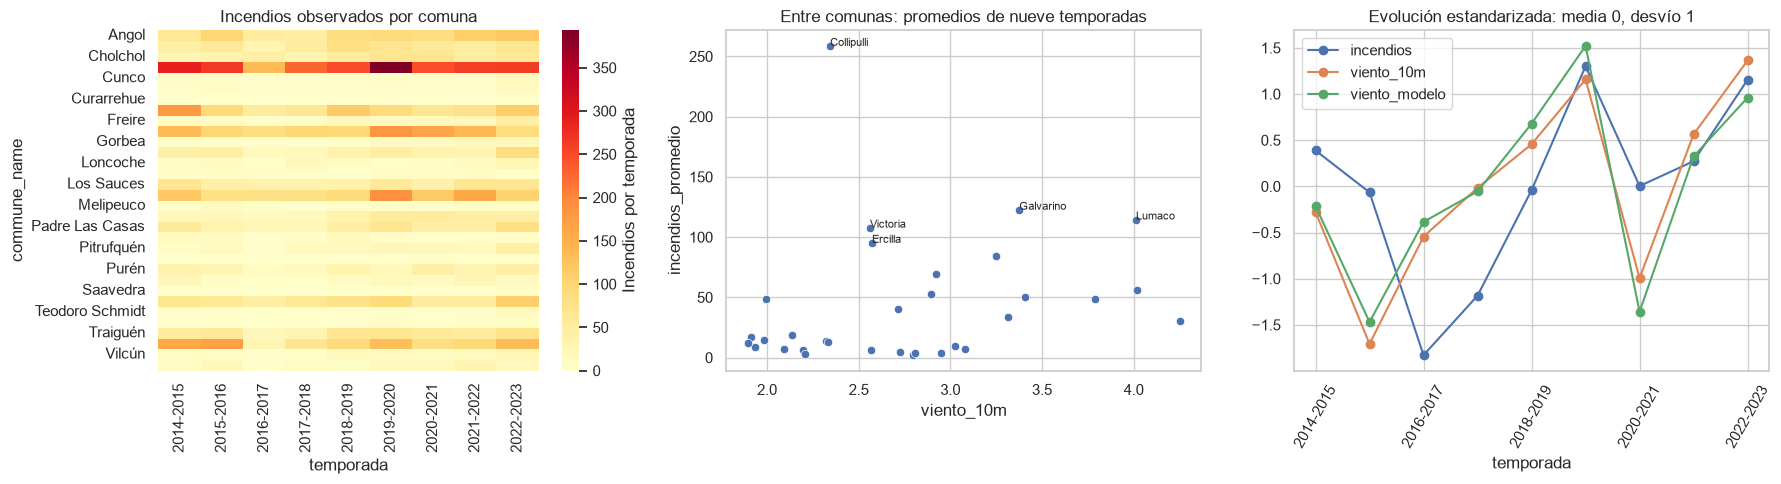

,incendios,viento_10m,viento_modelo
temporada,,,
2014-2015,1496.000,2.738,4.849
2015-2016,1344.000,2.620,4.689
2016-2017,753.000,2.716,4.828
2017-2018,969.000,2.760,4.870
2018-2019,1352.000,2.799,4.963
2019-2020,1802.000,2.858,5.071
2020-2021,1367.000,2.679,4.703
2021-2022,1457.000,2.808,4.918
2022-2023,1753.000,2.875,5.000


Media simple de viento entre comunas; no es una media regional ponderada por superficie.


In [3]:
resumen_t=panel_v.groupby('temporada').agg(incendios=('numero_incendios','sum'),viento_10m=('wind_speed_10m_ms','mean'),viento_modelo=('wind_speed_lowest_model_ms','mean'))
resumen_c=panel_v.groupby('commune_name').agg(incendios_promedio=('numero_incendios','mean'),viento_10m=('wind_speed_10m_ms','mean'))
fig,axs=plt.subplots(1,3,figsize=(18,5))
sns.heatmap(panel_v.pivot(index='commune_name',columns='temporada',values='numero_incendios'),cmap='YlOrRd',ax=axs[0],cbar_kws={'label':'Incendios por temporada'})
axs[0].set_title('Incendios observados por comuna')
sns.scatterplot(data=resumen_c,x='viento_10m',y='incendios_promedio',ax=axs[1])
for nombre in resumen_c.nlargest(5,'incendios_promedio').index:
    r=resumen_c.loc[nombre];axs[1].annotate(nombre,(r.viento_10m,r.incendios_promedio),fontsize=8)
axs[1].set_title('Entre comunas: promedios de nueve temporadas')
z=(resumen_t-resumen_t.mean())/resumen_t.std()
z.plot(marker='o',ax=axs[2]);axs[2].set_title('Evolución estandarizada: media 0, desvío 1')
axs[2].tick_params(axis='x',rotation=60)
plt.tight_layout();plt.show()
display(resumen_t)
print('Media simple de viento entre comunas; no es una media regional ponderada por superficie.')

## 11.3. Correlaciones y separación de efectos territoriales
Se compara Pearson y Spearman sobre conteos, además de Pearson sobre `log(1+incendios)`:

1. **Global:** las 288 comuna-temporadas mezcladas.
2. **Entre comunas:** 32 medias de comuna.
3. **Dentro de comuna:** se resta la media de cada comuna.
4. **Dentro de comuna y temporada:** se eliminan niveles de comuna y shocks comunes de temporada mediante doble centrado (panel balanceado).

En Spearman ajustado se centran los rangos globales de cada variable antes de correlacionarlos; es una correlación parcial de rangos, no Spearman directo de los residuos. No se aplican p-valores que traten las 288 filas como independientes.

,variable,comparacion,n,pearson_conteo,spearman_o_parcial_rangos,pearson_log1p
0,wind_speed_10m_ms,global,288,0.213,0.353,0.354
1,wind_speed_10m_ms,entre_comunas,32,0.217,0.332,0.369
2,wind_speed_10m_ms,comuna,288,0.267,0.308,0.259
3,wind_speed_10m_ms,comuna_temporada,288,0.091,0.064,-0.083
4,wind_speed_lowest_model_ms,global,288,0.240,0.325,0.313
5,wind_speed_lowest_model_ms,entre_comunas,32,0.241,0.266,0.324
6,wind_speed_lowest_model_ms,comuna,288,0.246,0.252,0.221
7,wind_speed_lowest_model_ms,comuna_temporada,288,0.075,0.044,-0.030
8,wind_u_10m_ms,global,288,-0.020,0.110,0.076
9,wind_u_10m_ms,entre_comunas,32,-0.050,0.081,0.057


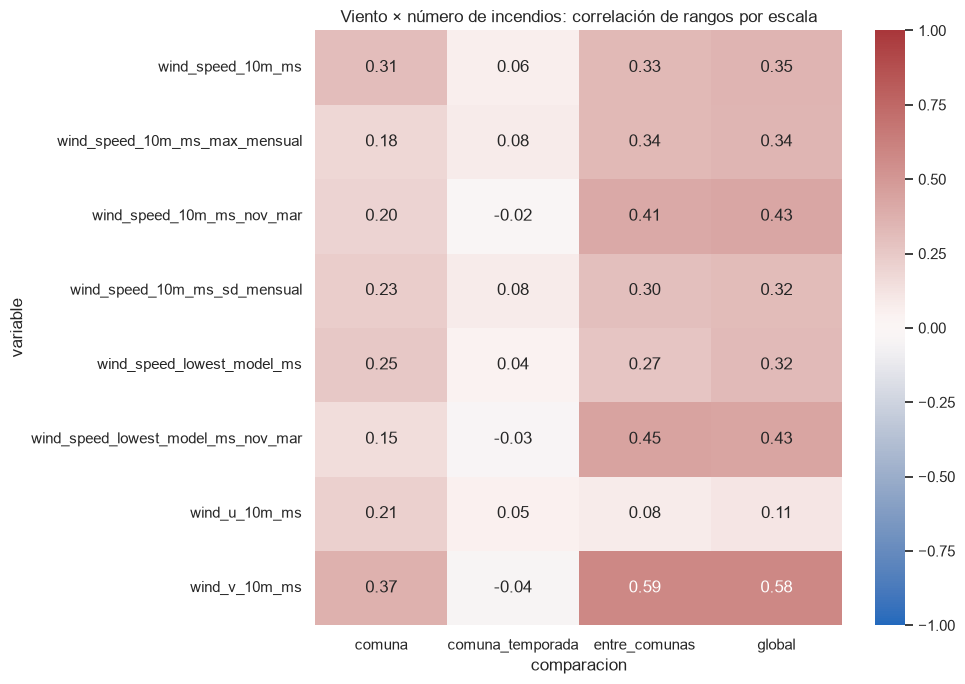

In [4]:
metricas_v=vientos+['wind_speed_10m_ms_max_mensual','wind_speed_10m_ms_sd_mensual','wind_speed_10m_ms_nov_mar','wind_speed_lowest_model_ms_nov_mar']
def residual_v(s,marco,modo):
    if modo=='global':return s-s.mean()
    if modo=='comuna':return s-s.groupby(marco.clave_comuna).transform('mean')
    return s-s.groupby(marco.clave_comuna).transform('mean')-s.groupby(marco.temporada).transform('mean')+s.mean()
resultados=[]
for v in metricas_v:
    for modo in ['global','entre_comunas','comuna','comuna_temporada']:
        if modo=='entre_comunas':
            t=panel_v.groupby('clave_comuna')[[v,'numero_incendios','log_incendios']].mean()
            xp,yp,yl=t[v],t.numero_incendios,t.log_incendios
            xr,yr=xp.rank(),yp.rank()
        else:
            xp=residual_v(panel_v[v],panel_v,modo)
            yp=residual_v(panel_v.numero_incendios,panel_v,modo)
            yl=residual_v(panel_v.log_incendios,panel_v,modo)
            xr=residual_v(panel_v[v].rank(),panel_v,modo)
            yr=residual_v(panel_v.numero_incendios.rank(),panel_v,modo)
        resultados.append({'variable':v,'comparacion':modo,'n':len(xp),'pearson_conteo':xp.corr(yp),'spearman_o_parcial_rangos':xr.corr(yr),'pearson_log1p':xp.corr(yl)})
correlaciones_v=pd.DataFrame(resultados)
display(correlaciones_v)
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(correlaciones_v.pivot(index='variable',columns='comparacion',values='spearman_o_parcial_rangos'),annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='vlag',ax=ax)
plt.title('Viento × número de incendios: correlación de rangos por escala')
plt.tight_layout();plt.show()

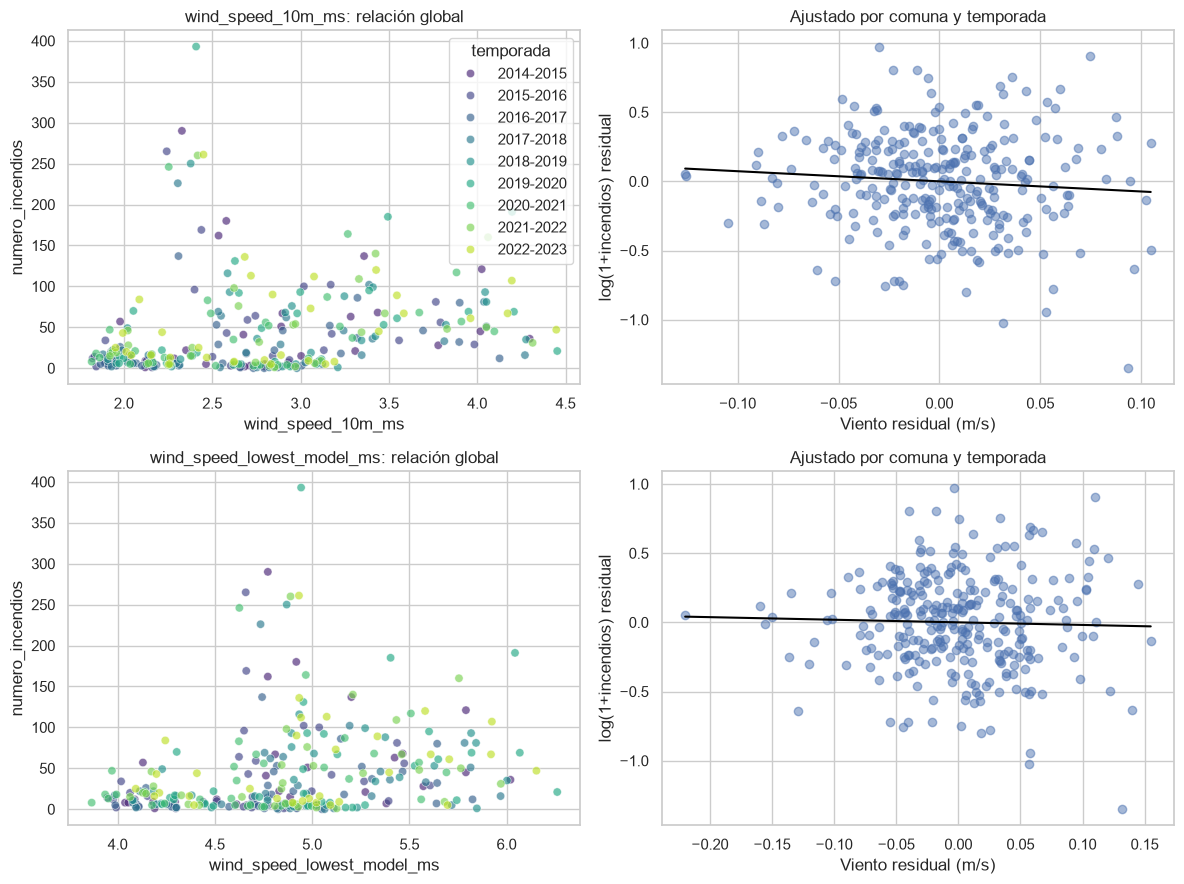

In [5]:
fig,axs=plt.subplots(2,2,figsize=(12,9))
for fila,v in enumerate(velocidades):
    sns.scatterplot(data=panel_v,x=v,y='numero_incendios',hue='temporada',palette='viridis',alpha=.65,ax=axs[fila,0],legend=fila==0)
    axs[fila,0].set_title(v+': relación global')
    x=residual_v(panel_v[v],panel_v,'comuna_temporada')
    y=residual_v(panel_v.log_incendios,panel_v,'comuna_temporada')
    axs[fila,1].scatter(x,y,alpha=.5)
    b=np.polyfit(x,y,1);xx=np.linspace(x.min(),x.max(),100)
    axs[fila,1].plot(xx,np.polyval(b,xx),color='black')
    axs[fila,1].set(xlabel='Viento residual (m/s)',ylabel='log(1+incendios) residual',title='Ajustado por comuna y temporada')
plt.tight_layout();plt.show()

## 11.4. ¿La relación se repite en las comunas?
Cada coeficiente comunal usa solo nueve temporadas: su signo es inestable. Se reporta su distribución, sin declarar comunas “significativas” ni seleccionar solo las que apoyan una hipótesis. Se contrasta también la serie regional de conteos con el promedio simple de viento, cuya muestra temporal es de nueve puntos.

In [6]:
por_comuna=[]
for nombre,g in panel_v.groupby('commune_name'):
    r={'comuna':nombre,'n_temporadas':len(g),'incendios_media':g.numero_incendios.mean()}
    for v in velocidades:r[v]=g[v].corr(g.numero_incendios,method='spearman')
    por_comuna.append(r)
por_comuna=pd.DataFrame(por_comuna)
display(por_comuna.sort_values('wind_speed_10m_ms'))
display(pd.DataFrame({v:{'mediana_rho':por_comuna[v].median(),'comunas_positivas':por_comuna[v].gt(0).sum(),'comunas_negativas':por_comuna[v].lt(0).sum()} for v in velocidades}).T)
regional_v=pd.DataFrame([{'variable':v,'rho_9_temporadas':resumen_t[col].corr(resumen_t.incendios,method='spearman')} for v,col in [('wind_speed_10m_ms','viento_10m'),('wind_speed_lowest_model_ms','viento_modelo')]])
display(regional_v)

,comuna,n_temporadas,incendios_media,wind_speed_10m_ms,wind_speed_lowest_model_ms
13,Lonquimay,9,7.444,-0.622,-0.437
5,Curacautín,9,6.222,-0.155,-0.138
31,Villarrica,9,14.222,0.000,-0.133
19,Perquenco,9,9.556,0.017,0.343
9,Galvarino,9,122.667,0.033,0.109
16,Melipeuco,9,5.889,0.151,0.100
29,Victoria,9,107.778,0.167,0.117
6,Curarrehue,9,2.000,0.173,0.069
22,Purén,9,30.222,0.200,0.250
12,Loncoche,9,12.111,0.201,0.050


,mediana_rho,comunas_positivas,comunas_negativas
wind_speed_10m_ms,0.400,29.000,2.000
wind_speed_lowest_model_ms,0.409,29.000,3.000


,variable,rho_9_temporadas
0,wind_speed_10m_ms,0.650
1,wind_speed_lowest_model_ms,0.633


## 11.5. Sensibilidad: ¿una temporada o comuna domina el resultado?
Se recalcula la correlación ajustada omitiendo una temporada y luego una comuna. Los rangos son diagnósticos de sensibilidad, **no intervalos de confianza**. No se interpreta el mínimo/máximo como incertidumbre estadística formal.

In [7]:
sensibilidad=[]
for v in metricas_v:
    for columna in ['temporada','clave_comuna']:
        vals=[]
        for excluido in panel_v[columna].unique():
            t=panel_v.loc[panel_v[columna].ne(excluido)]
            vals.append(residual_v(t[v].rank(),t,'comuna_temporada').corr(residual_v(t.numero_incendios.rank(),t,'comuna_temporada')))
        sensibilidad.append({'variable':v,'omitir_una':columna,'min_rho':min(vals),'max_rho':max(vals),'signo_consistente':all(x>0 for x in vals) or all(x<0 for x in vals)})
sensibilidad_v=pd.DataFrame(sensibilidad)
display(sensibilidad_v)

,variable,omitir_una,min_rho,max_rho,signo_consistente
0,wind_speed_10m_ms,temporada,0.016,0.121,True
1,wind_speed_10m_ms,clave_comuna,0.037,0.103,True
2,wind_speed_lowest_model_ms,temporada,-0.038,0.071,False
3,wind_speed_lowest_model_ms,clave_comuna,0.029,0.063,True
4,wind_u_10m_ms,temporada,-0.005,0.077,False
5,wind_u_10m_ms,clave_comuna,0.031,0.104,True
6,wind_v_10m_ms,temporada,-0.089,0.002,False
7,wind_v_10m_ms,clave_comuna,-0.071,0.018,False
8,wind_speed_10m_ms_max_mensual,temporada,0.047,0.121,True
9,wind_speed_10m_ms_max_mensual,clave_comuna,0.064,0.099,True


## 11.6. Ajuste exploratorio por calor, humedad y precipitación
Regresión lineal de `log(1+incendios)` con efectos fijos de comuna y temporada. Cada variable de viento entra **en un modelo separado** para evitar mezclar velocidades y componentes muy relacionadas. Se compara el ajuste con y sin temperatura media, humedad relativa media y precipitación acumulada de la temporada.

El coeficiente corresponde a un aumento de una desviación estándar del viento **residual tras quitar comuna y temporada**. Se presenta en unidades de log(1+conteo), sin transformarlo a porcentaje exacto de incendios. Esto no es un modelo Poisson ni una estimación causal; los controles contemporáneos pueden compartir información y quedan factores omitidos. Se reportan estabilidad al omitir temporadas y colinealidad, sin errores estándar ingenuos.

In [8]:
def ajustar_v(t,v,ajustado):
    columnas=[v]+(controles_v if ajustado else [])
    X=pd.DataFrame({x:residual_v(t[x],t,'comuna_temporada') for x in columnas})
    escalas=X.std(ddof=1)
    assert escalas.gt(0).all()
    X=X/escalas
    y=residual_v(t.log_incendios,t,'comuna_temporada')
    beta=np.linalg.lstsq(X.to_numpy(),y.to_numpy(),rcond=None)[0]
    return beta[0],np.linalg.cond(X.to_numpy())
modelos=[]
for v in vientos:
    for ajuste in [False,True]:
        beta,cond=ajustar_v(panel_v,v,ajuste)
        loo=[ajustar_v(panel_v.loc[panel_v.temporada.ne(s)],v,ajuste)[0] for s in panel_v.temporada.unique()]
        modelos.append({'viento':v,'controles_climaticos':ajuste,'beta_por_SD_residual':beta,'min_beta_sin_una_temporada':min(loo),'max_beta_sin_una_temporada':max(loo),'numero_condicion_X':cond})
modelos_v=pd.DataFrame(modelos)
display(modelos_v)

,viento,controles_climaticos,beta_por_SD_residual,min_beta_sin_una_temporada,max_beta_sin_una_temporada,numero_condicion_X
0,wind_speed_10m_ms,False,-0.029,-0.045,-0.001,1.000
1,wind_speed_10m_ms,True,-0.037,-0.052,-0.005,5.106
2,wind_speed_lowest_model_ms,False,-0.011,-0.025,0.008,1.000
3,wind_speed_lowest_model_ms,True,-0.014,-0.028,0.006,5.056
4,wind_u_10m_ms,False,-0.011,-0.028,0.001,1.000
5,wind_u_10m_ms,True,-0.027,-0.036,-0.008,5.142
6,wind_v_10m_ms,False,-0.037,-0.055,-0.025,1.000
7,wind_v_10m_ms,True,-0.068,-0.088,-0.025,5.681


## 11.7. Contraste interpretable: temporadas relativamente más y menos ventosas
Para cada comuna se ordenan sus nueve temporadas por velocidad a 10 m: tercio bajo, medio y alto (tres temporadas por grupo). Se comparan medias de incendios dando igual peso a cada comuna. No son grupos experimentales: aún pueden diferir por temporada, clima y exposición. Se informa cuánto cambia cada comuna, además del resumen global.

,incendios,viento
tercio_viento,,
Bajo,38.510,2.665
Medio,38.000,2.769
Alto,51.542,2.850


tercio_viento,Alto,Bajo,Medio,diferencia_alto_menos_bajo
commune_name,,,,
Lumaco,152.667,92.667,98.333,60.000
Collipulli,304.667,245.667,225.667,59.000
Angol,108.000,79.667,65.667,28.333
Los Sauces,65.000,38.667,47.667,26.333
Temuco,86.333,61.000,61.333,25.333
Ercilla,93.667,72.000,120.000,21.667
Padre Las Casas,66.667,46.000,32.333,20.667
Galvarino,138.000,117.333,112.667,20.667
Traiguén,64.333,45.667,49.333,18.667


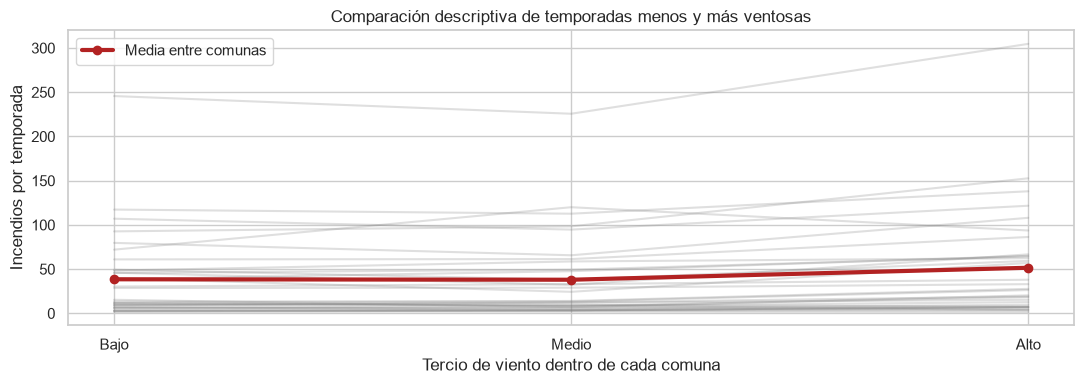

In [9]:
t=panel_v.sort_values(['clave_comuna','wind_speed_10m_ms','temporada']).copy()
t['tercio_viento']=t.groupby('clave_comuna').cumcount().floordiv(3).map({0:'Bajo',1:'Medio',2:'Alto'})
tercios=t.groupby(['commune_name','tercio_viento']).agg(incendios=('numero_incendios','mean'),viento=('wind_speed_10m_ms','mean')).reset_index()
display(tercios.groupby('tercio_viento')[['incendios','viento']].mean().reindex(['Bajo','Medio','Alto']))
cambio=tercios.pivot(index='commune_name',columns='tercio_viento',values='incendios')
cambio['diferencia_alto_menos_bajo']=cambio.Alto-cambio.Bajo
display(cambio.sort_values('diferencia_alto_menos_bajo',ascending=False))
fig,ax=plt.subplots(figsize=(11,4))
for com,g in tercios.groupby('commune_name'):
    ax.plot(['Bajo','Medio','Alto'],g.set_index('tercio_viento').reindex(['Bajo','Medio','Alto']).incendios,alpha=.25,color='gray')
ax.plot(['Bajo','Medio','Alto'],tercios.groupby('tercio_viento').incendios.mean().reindex(['Bajo','Medio','Alto']),color='firebrick',marker='o',lw=3,label='Media entre comunas')
ax.set(xlabel='Tercio de viento dentro de cada comuna',ylabel='Incendios por temporada',title='Comparación descriptiva de temporadas menos y más ventosas')
ax.legend();plt.tight_layout();plt.show()

## 11.8. Hallazgos numéricos y alcance
Los resultados siguientes se generan desde el cruce, sin fijar de antemano el signo de la asociación. Las métricas secundarias y los modelos son exploratorios y no equivalen a múltiples pruebas confirmatorias independientes.

In [10]:
textos=[]
for v in velocidades:
    r=correlaciones_v[correlaciones_v.variable.eq(v)].set_index('comparacion')
    s=sensibilidad_v[(sensibilidad_v.variable==v)&(sensibilidad_v.omitir_una=='temporada')].iloc[0]
    m=modelos_v[(modelos_v.viento==v)&modelos_v.controles_climaticos].iloc[0]
    textos.append(f'- **`{v}`**: correlación de rangos global **{r.loc["global","spearman_o_parcial_rangos"]:.3f}**; entre comunas **{r.loc["entre_comunas","spearman_o_parcial_rangos"]:.3f}**; dentro de comuna **{r.loc["comuna","spearman_o_parcial_rangos"]:.3f}**; ajustada por comuna y temporada **{r.loc["comuna_temporada","spearman_o_parcial_rangos"]:.3f}**. Al omitir una temporada, esta última varía entre **{s.min_rho:.3f} y {s.max_rho:.3f}**.')
    if v in modelos_v.viento.values:
        textos.append(f'  Con controles climáticos, coeficiente estandarizado residual = **{m.beta_por_SD_residual:.3f}** en log(1+incendios).')
display(Markdown((chr(10)*2).join(textos)))
principal=correlaciones_v[(correlaciones_v.variable=='wind_speed_10m_ms')&(correlaciones_v.comparacion=='comuna_temporada')].iloc[0]
rho=principal.spearman_o_parcial_rangos
calificacion='débil' if abs(rho)<.3 else ('moderada' if abs(rho)<.6 else 'fuerte')
display(Markdown(f'**Lectura principal:** la asociación de rangos del viento a 10 m con el número de incendios, descontando comuna y temporada, es descriptivamente **{calificacion}** (r = {rho:.3f}; clasificación orientativa). La comparación entre escalas muestra cuánto cambia la relación al controlar diferencias territoriales y temporadas comunes. No se ha demostrado causalidad ni capacidad predictiva fuera de muestra.'))

- **`wind_speed_10m_ms`**: correlación de rangos global **0.353**; entre comunas **0.332**; dentro de comuna **0.308**; ajustada por comuna y temporada **0.064**. Al omitir una temporada, esta última varía entre **0.016 y 0.121**.

  Con controles climáticos, coeficiente estandarizado residual = **-0.037** en log(1+incendios).

- **`wind_speed_lowest_model_ms`**: correlación de rangos global **0.325**; entre comunas **0.266**; dentro de comuna **0.252**; ajustada por comuna y temporada **0.044**. Al omitir una temporada, esta última varía entre **-0.038 y 0.071**.

  Con controles climáticos, coeficiente estandarizado residual = **-0.014** en log(1+incendios).

**Lectura principal:** la asociación de rangos del viento a 10 m con el número de incendios, descontando comuna y temporada, es descriptivamente **débil** (r = 0.064; clasificación orientativa). La comparación entre escalas muestra cuánto cambia la relación al controlar diferencias territoriales y temporadas comunes. No se ha demostrado causalidad ni capacidad predictiva fuera de muestra.

**Qué permite concluir este cruce:** relacionar promedios y variabilidad mensual del viento con conteos observados por comuna-temporada, y examinar la estabilidad territorial y temporal de esa relación.

**Qué queda fuera:** velocidad o dirección el día del incendio, ráfagas, duración, superficie quemada y propagación. Las componentes U/V son promedios firmados y no permiten identificar de qué dirección soplaba el viento al iniciarse cada incendio. Los máximos mensuales aquí son máximos de medias mensuales.

**Lectura para el proyecto:** priorizar la comparación dentro de comuna y con ajuste de temporada frente a la correlación global. Si esta cambia al ajustar, la diferencia es información sobre confusión espacial/temporal, no una contradicción. Hay solo nueve temporadas completas y las comunas comparten píxeles meteorológicos; no se tratan 288 filas como réplicas independientes. Los promedios de viento de la temporada se conocen al terminarla, por lo que estos resultados son retrospectivos, no pronósticos anticipados.